# Analisis de texto

### Importamos librerias

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from collections import Counter
from wordcloud import WordCloud

### Carga de datos

In [5]:
#traendo los datos de biare
df_biare = pd.read_csv("../Limpieza de datos (Practica 1)/biare_limpio_2021_2024.csv")
#marcamos las columnas que tienen texto
columnas_texto = ['cs_C_ACT', 'cs_OCU', 'cs_A_ECO', 'cs_POS']


### Creamos el texto de cada persona

In [7]:
#creamos una nueva columna que contenga todo el texto de las columnas de texto
df_biare['texto_perfil'] = df_biare[columnas_texto].astype(str).agg(' '.join, axis=1)

#mostramos los primeros 10 textos de la nueva columna
print(df_biare['texto_perfil'].head(10).tolist())

['Espera respuesta a una solicitud de trabajo No trabaja No trabaja No trabaja', 'Trabajó por lo menos una hora para obtener ingresos Profesionistas y técnicos Industria Trabajador(a) a sueldo fijo, salario o jornal', 'Trabajó por lo menos una hora para obtener ingresos Comerciantes, vendedores y similares Comercio Trabajador(a) por su cuenta', 'Trabajó por lo menos una hora para obtener ingresos Profesionistas y técnicos Servicios Trabajador(a) a sueldo fijo, salario o jornal', 'Trabajó por lo menos una hora para obtener ingresos Comerciantes, vendedores y similares Comercio Trabajador(a) a sueldo fijo, salario o jornal', 'Trabajó por lo menos una hora para obtener ingresos Trabajadores en servicios personales y conductores de vehículos Servicios Trabajador(a) a sueldo fijo, salario o jornal', 'Se dedica a los quehaceres del hogar No trabaja No trabaja No trabaja', 'Buscó trabajo No trabaja No trabaja No trabaja', 'Trabajó por lo menos una hora para obtener ingresos Comerciantes, vend

### limpiamos el texto

In [14]:
#creamos una lista con los nexos que queremos eliminar del texto para dejar solo las palabras importantes
nexos = ['de', 'del', 'a', 'una', 'un', 'por', 'lo', 'para', 'o', 'y', 'en', 'el', 'la', 'los', 'las', 'su', 'con', 'que', 'se', 'dedica', 'menos', 'hora', 'obtener']

#convertimos las palabras a minusculas, eliminamos los nexos y los signos de puntuacion, eliminamos las palabras mal escritas y eliminamos las palabras repetidas
def limpiar(texto):
    texto = texto.lower()
    texto = texto.replace('no trabaja', 'notrabaja').replace('no especificado', 'noespecificado')
    texto = re.sub(r'[^a-záéíóúñü\s]', ' ', texto)
    palabras = [p for p in texto.split() if p not in nexos]
    return list(dict.fromkeys(palabras))

#aplicamos la funcion limpiar a la columna de texto_perfil y creamos una nueva columna tokens
df_biare['tokens'] = df_biare['texto_perfil'].apply(limpiar)

#creamos un conteo de las palabras distintas en la columna tokens
conteo = Counter(df_biare['tokens'].explode())

#mostramos los primeros 2 textos de la columna tokens y el conteo de palabras distintas y las 15 palabras más comunes
print(df_biare['tokens'].head(2).tolist())
print("\nPalabras distintas:", len(conteo))
print("\nPalabras más comunes:")
print(conteo.most_common(15))

[['espera', 'respuesta', 'solicitud', 'trabajo', 'notrabaja'], ['trabajó', 'ingresos', 'profesionistas', 'técnicos', 'industria', 'trabajador', 'sueldo', 'fijo', 'salario', 'jornal']]

Palabras distintas: 66

Palabras más comunes:
[('trabajó', 5071), ('ingresos', 4976), ('trabajador', 4960), ('sueldo', 3449), ('fijo', 3449), ('salario', 3449), ('jornal', 3449), ('notrabaja', 2948), ('servicios', 2745), ('trabajadores', 2191), ('quehaceres', 1684), ('hogar', 1684), ('personales', 1505), ('conductores', 1505), ('vehículos', 1505)]


### Grafica de distribución de las palabras más usadas

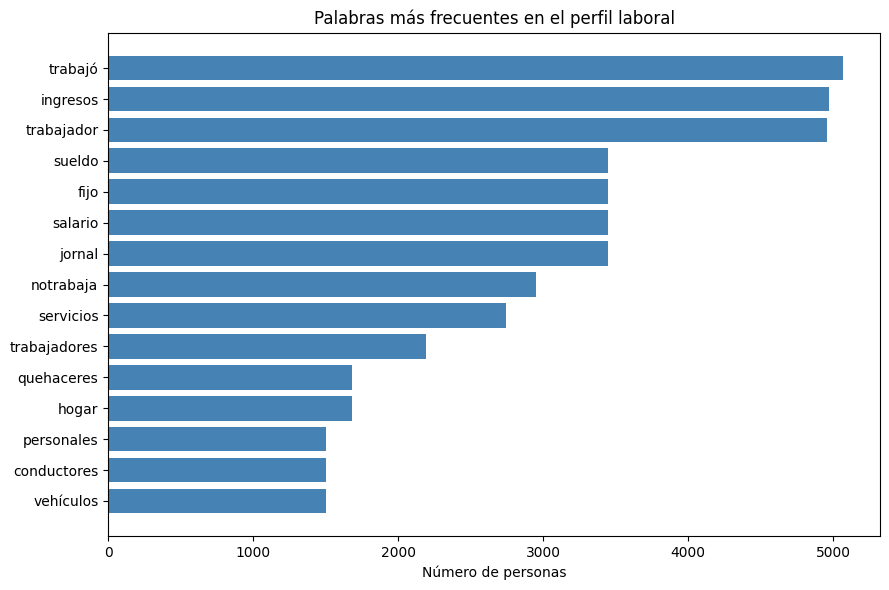

In [18]:
#guardamos las 15 palabras más comunes y sus frecuencias en listas separadas para graficarlas
top = conteo.most_common(15)
palabras = [p for p, n in top]
frecuencias = [n for p, n in top]

plt.figure(figsize=(9, 6))
plt.barh(palabras[::-1], frecuencias[::-1], color='steelblue')
plt.xlabel('Número de personas')
plt.title('Palabras más frecuentes en el perfil laboral')
plt.tight_layout()
plt.show()

### Hacemos la nube de palabras

Hacemos una nube de texto para ver las palabras que mas aparecen en nuestro dataset

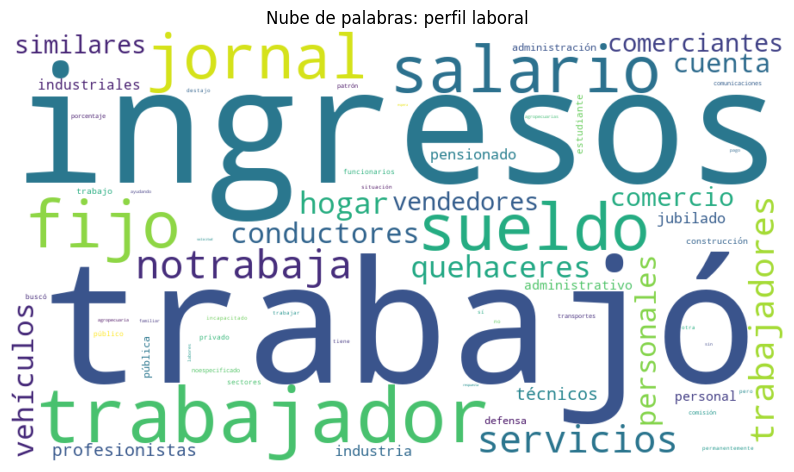

In [17]:
nube = WordCloud(width=900, height=500, background_color='white',
                 stopwords=set(nexos), collocations=False)
nube.generate_from_frequencies(conteo)

plt.figure(figsize=(10, 6))
plt.imshow(nube, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de palabras: perfil laboral')
plt.show()

### Comparacion entre alta satisfacción y baja satisfacción con palabras

Comparamos la aparición de las palabras en las dos mediciones que tenemos con la satisfacción con la vida como alta y baja.

In [22]:
#definimos como satisfaccion con la vida baja los que tienen entre 0 y 6 puntos, media los de 7 y 8, y alta los que tienen 9 o más puntos
baja = df_biare[(df_biare['cb_P1'] >= 0) & (df_biare['cb_P1'] <= 6)]
media = df_biare[(df_biare['cb_P1'] >= 7) & (df_biare['cb_P1'] <= 8)]
alta = df_biare[df_biare['cb_P1'] >= 9]

#creamos un conteo de las palabras distintas en la columna tokens para cada grupo de satisfaccion con la vida
conteo_baja = Counter(baja['tokens'].explode())
conteo_media = Counter(media['tokens'].explode())
conteo_alta = Counter(alta['tokens'].explode())

#creamos un dataframe con las palabras distintas y sus apariciones en cada grupo de satisfaccion con la vida
comp_texto = pd.DataFrame({
    'baja_%': pd.Series(conteo_baja) / len(baja) * 100,
    'media_%': pd.Series(conteo_media) / len(media) * 100,
    'alta_%': pd.Series(conteo_alta) / len(alta) * 100
}).fillna(0)
comp_texto['diferencia'] = comp_texto['alta_%'] - comp_texto['baja_%'] #creamos una columna con la diferencia entre la frecuencia de las palabras en el grupo de satisfaccion con la vida alta y baja

print("Personas en baja:", len(baja), "| en media:", len(media), "| en alta:", len(alta))
print(comp_texto.sort_values('diferencia').head(8).round(1))
print(comp_texto.sort_values('diferencia').tail(8).round(1))

print(comp_texto.loc[['notrabaja', 'hogar', 'sueldo', 'servicios', 'incapacitado'],
                     ['baja_%', 'media_%', 'alta_%']].round(1))

Personas en baja: 799 | en media: 3147 | en alta: 4073
              baja_%  media_%  alta_%  diferencia
notrabaja       43.4     37.3    35.0        -8.4
quehaceres      26.7     21.3    19.7        -7.0
hogar           26.7     21.3    19.7        -7.0
comercio        17.0     14.9    14.3        -2.7
otra             2.3      0.8     0.4        -1.8
situación        2.3      0.8     0.4        -1.8
trabajar         2.1      0.8     0.4        -1.7
incapacitado     2.1      0.8     0.4        -1.7
            baja_%  media_%  alta_%  diferencia
servicios     28.4     33.9    35.6         7.2
trabajador    55.4     61.6    63.3         7.9
trabajó       56.6     62.7    65.0         8.4
ingresos      55.1     61.6    63.8         8.7
fijo          35.3     42.4    45.0         9.7
salario       35.3     42.4    45.0         9.7
jornal        35.3     42.4    45.0         9.7
sueldo        35.3     42.4    45.0         9.7
              baja_%  media_%  alta_%
notrabaja       43.4     

Como podemos ver en ambas mediciones de la satisfacción con la vida, tanto en la alta, media, como en la baja, la cantidad de veces que se repiten las referencias hacia el trabajo y hacia el dinero o los ingresos, es muy gramde, por lo que podemos decir que tanto el trabajo como el dinero, son un factor importante en la satisfacción con la vida, lo cual no sorprende pues a final de cuentas todo en esta vida cuesta, sin embargo, preocupa que solamente acciones y no palabras como familia o pareja sean las que más aparecen, lo que podría llevarnos a deducir que todo en la vida tiene que ver con trabajo y dinero.